<a href="https://colab.research.google.com/github/diloo11/PCVK_Ganjil_2026/blob/main/Week_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2 as cv
import math
from google.colab.patches import cv2_imshow
from PIL import Image as im

In [6]:
def convolution2d(image, kernel, stride=1, padding=0):
    # Konversi citra ke grayscale jika citranya berwarna (3 channel)
    if len(image.shape) == 3:
        image = cv.cvtColor(image, cv.COLOR_RGB2GRAY)

    # 1. Menambahkan padding pada citra
    image_padded = np.pad(image, ((padding, padding), (padding, padding)), mode='constant', constant_values=0)

    i_h, i_w = image_padded.shape
    k_h, k_w = kernel.shape

    # 2. Menghitung dimensi output (tinggi dan lebar)
    out_h = int((i_h - k_h) / stride) + 1
    out_w = int((i_w - k_w) / stride) + 1

    # Inisialisasi matriks output dengan nilai 0
    output = np.zeros((out_h, out_w))

    # 3. Proses konvolusi (sliding window)
    for y in range(out_h):
        for x in range(out_w):
            # Tentukan batas region pada citra yang sudah dipada
            y_start = y * stride
            y_end = y_start + k_h
            x_start = x * stride
            x_end = x_start + k_w

            # Ambil potongan matriks (patch)
            region = image_padded[y_start:y_end, x_start:x_end]

            # Lakukan perkalian elemen-per-elemen (element-wise multiplication) dan jumlahkan
            output[y, x] = np.sum(region * kernel)

    return output

In [3]:
img = cv.imread('/content/drive/MyDrive/lena.jpg')
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

In [4]:
kernel_sharpen = np.array([[ 0, -1,  0],
                           [-1,  5, -1],
                           [ 0, -1,  0]])

In [7]:
img_convolved = convolution2d(img_gray, kernel_sharpen, 1, 2)

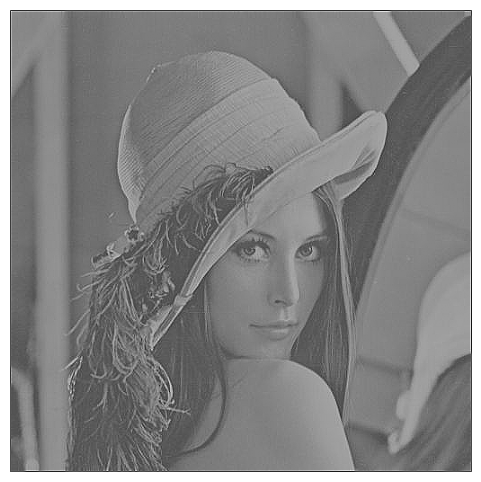

In [8]:
plt.figure(figsize=(6, 6))
plt.imshow(img_convolved, cmap='gray')
plt.axis('off')
plt.show()

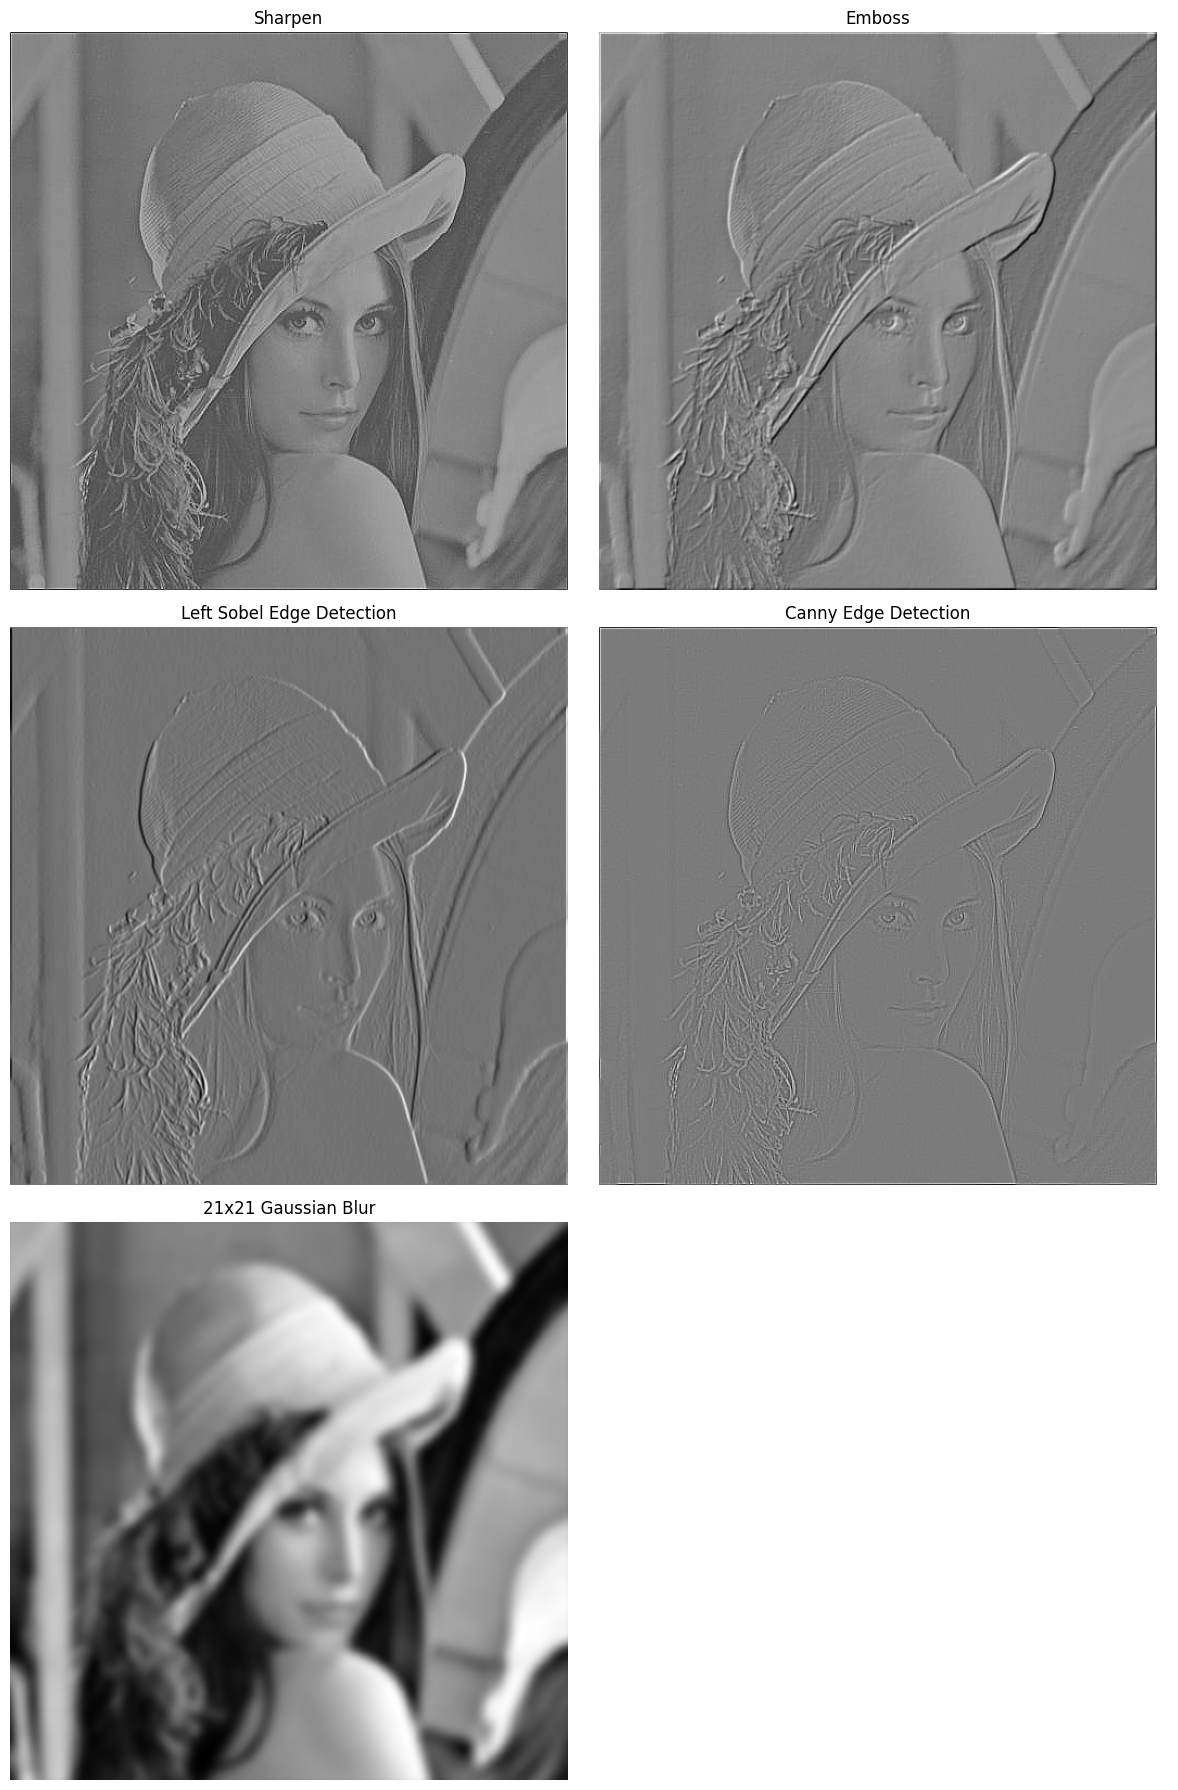

In [12]:
# 1. Menyiapkan semua kernel
kernel_sharpen = np.array([[ 0, -1,  0],
                           [-1,  5, -1],
                           [ 0, -1,  0]])

kernel_emboss = np.array([[-2, -1,  0],
                           [-1,  1,  1],
                           [ 0,  1,  2]])

kernel_sobel = np.array([[ 1,  0, -1],
                         [ 2,  0, -2],
                         [ 1,  0, -1]])

kernel_canny = np.array([[-1, -1, -1],
                         [-1,  8, -1],
                         [-1, -1, -1]])

kernel_size = 21
sigma = math.sqrt(kernel_size)
gaussian_kernel = cv.getGaussianKernel(kernel_size, sigma)
gaussian_kernel = gaussian_kernel @ gaussian_kernel.transpose()

# 2. Menerapkan fungsi konvolusi ke masing-masing kernel
img_sharpen = convolution2d(img_gray, kernel_sharpen, 1, 2)
img_emboss = convolution2d(img_gray, kernel_emboss, 1, 2)
img_sobel = convolution2d(img_gray, kernel_sobel, 1, 2)
img_canny = convolution2d(img_gray, kernel_canny, 1, 2)
img_gaussian = convolution2d(img_gray, gaussian_kernel, 1, 2)

# 3. Menampilkan kelima hasil gambar menggunakan matplotlib (grid 3x2)
fig, axes = plt.subplots(3, 2, figsize=(12, 18))

filters = [
    (img_sharpen, 'Sharpen'),
    (img_emboss, 'Emboss'),
    (img_sobel, 'Left Sobel Edge Detection'),
    (img_canny, 'Canny Edge Detection'),
    (img_gaussian, '21x21 Gaussian Blur')
]

for idx, (img_res, title) in enumerate(filters):
    row = idx // 2
    col = idx % 2
    axes[row, col].imshow(img_res, cmap='gray')
    axes[row, col].set_title(title)
    axes[row, col].axis('off')

# Menyembunyikan subplot terakhir yang kosong
axes[2, 1].axis('off')

plt.tight_layout()
plt.show()

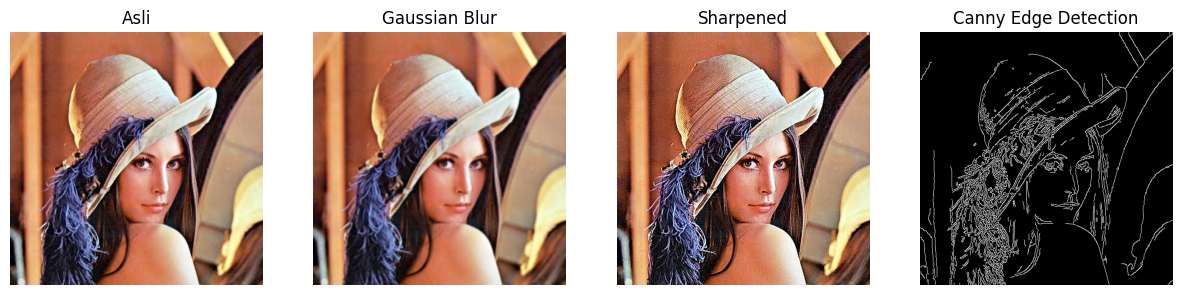

In [15]:
# Fungsi tampil berdampingan
def show_side_by_side(images, titles, figsize=(15,5)):
    plt.figure(figsize=figsize)
    for i, (img, title) in enumerate(zip(images, titles)):
        if len(img.shape) == 2:  # grayscale
            plt.subplot(1, len(images), i+1)
            plt.imshow(img, cmap="gray")
        else:  # color
            plt.subplot(1, len(images), i+1)
            plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis("off")
    plt.show()

# Memuat gambar (sesuaikan path dengan direktori Google Drive Anda)
img = cv.imread("/content/drive/MyDrive/lena.jpg")
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Menerapkan filter menggunakan library OpenCV
blur = cv.GaussianBlur(img, (7, 7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0, -1, 0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)

# Menampilkan gambar secara berdampingan
show_side_by_side([img, blur, sharpened, edges],
                  ["Asli", "Gaussian Blur", "Sharpened", "Canny Edge Detection"])

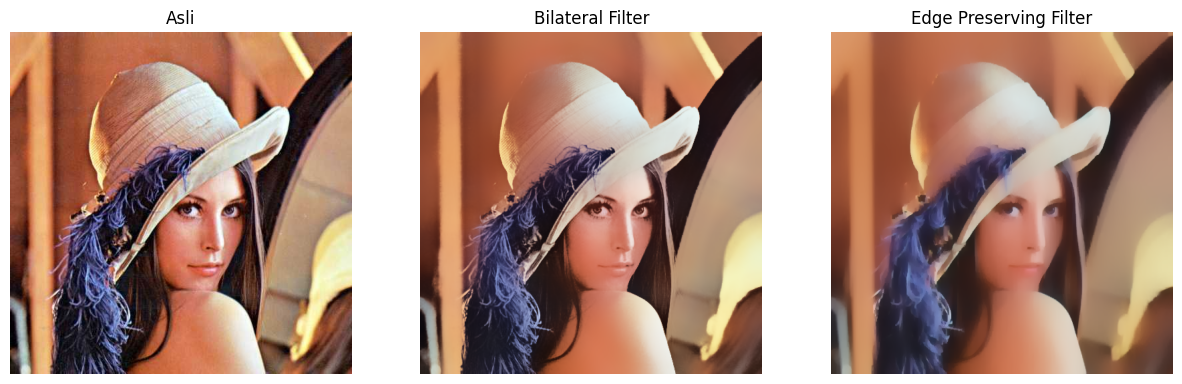

In [17]:
# Filter Modern dari OpenCV
# Bilateral Filter (edge-preserving)
bilateral = cv.bilateralFilter(img, 50, 100, 100)

# Edge Preserving Filter (alternatif Guided Filter)
edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)

# Menampilkan hasil gambar secara berdampingan
show_side_by_side([img, bilateral, edge_preserve],
                  ["Asli", "Bilateral Filter", "Edge Preserving Filter"])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step


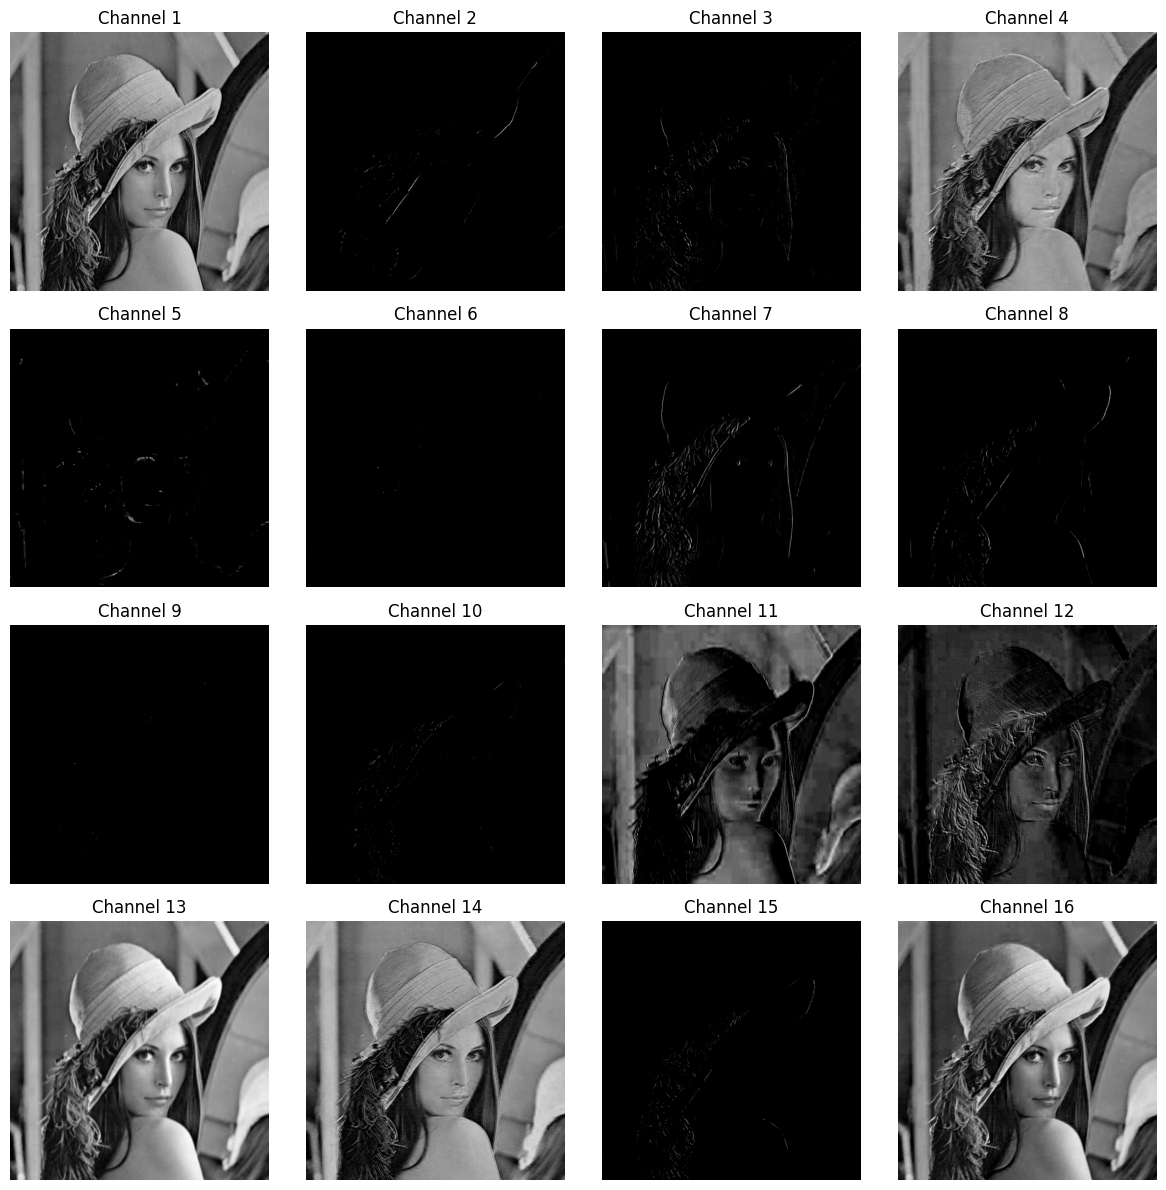

In [18]:
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Menyiapkan model CNN sederhana dengan 1 layer Conv2D
model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', input_shape=(img.shape[0], img.shape[1], 3))
])

# 2. Reshape gambar agar sesuai dengan input model (Batch size = 1)
img_expanded = np.expand_dims(img, axis=0).astype('float32') / 255.0

# 3. Mendapatkan hasil feature map dari layer konvolusi
feature_maps = model.predict(img_expanded)

# 4. Menampilkan beberapa channel dari feature map
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for i in range(16):
    row = i // 4
    col = i % 4
    axes[row, col].imshow(feature_maps[0, :, :, i], cmap='gray')
    axes[row, col].set_title(f'Channel {i+1}')
    axes[row, col].axis('off')

plt.tight_layout()
plt.show()

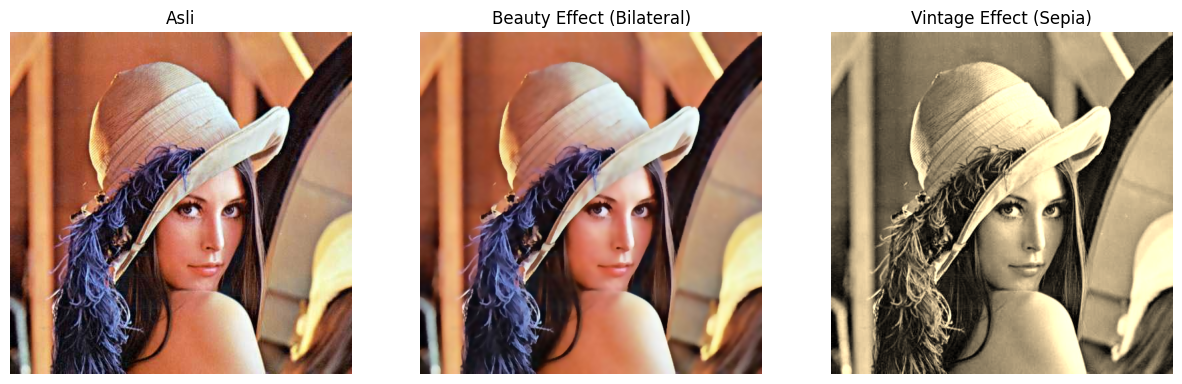

In [19]:
# --- Efek Beauty (Smooth skin dengan mempertahankan bagian tepi) ---
# Menggunakan bilateral filter yang dikombinasikan dengan sedikit peningkatan kontras
beauty = cv.bilateralFilter(img, d=9, sigmaColor=75, sigmaSpace=75)

# --- Efek Vintage (Kombinasi Sepia Tone & Vignette / Filter Tradisional) ---
# 1. Konversi ke float untuk manipulasi matriks warna
img_float = img.astype(np.float32) / 255.0

# 2. Menerapkan matriks transformasi warna Sepia (Vintage look)
sepia_kernel = np.array([[0.272, 0.534, 0.131],
                         [0.349, 0.686, 0.168],
                         [0.393, 0.769, 0.189]])
vintage = cv.transform(img_float, sepia_kernel)
vintage = np.clip(vintage, 0, 1) # Batasi nilai antara 0 dan 1
vintage = (vintage * 255).astype(np.uint8)

# Menampilkan hasil Experiment 4 secara berdampingan
show_side_by_side([img, beauty, vintage],
                  ["Asli", "Beauty Effect (Bilateral)", "Vintage Effect (Sepia)"])

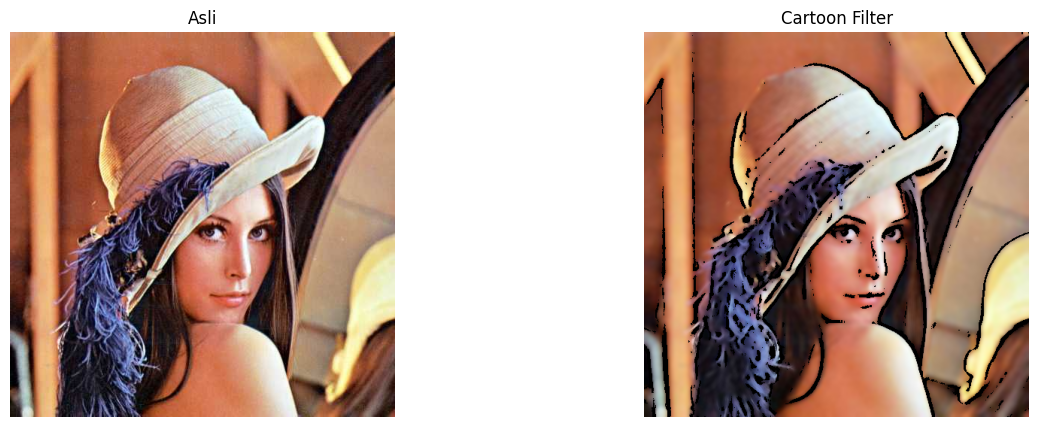

In [20]:
# Filter Anime / Cartoon
# Step 1: Edge detection (pakai median blur dulu agar gambar menjadi lebih halus)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray, 7)
edges = cv.adaptiveThreshold(gray_blur, 255,
                            cv.ADAPTIVE_THRESH_MEAN_C,
                            cv.THRESH_BINARY, 9, 9)

# Step 2: Bilateral filter untuk smoothing warna
color = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)

# Step 3: Gabungkan (cartoonize)
cartoon = cv.bitwise_and(color, color, mask=edges)

# Tampilkan
show_side_by_side([img, cartoon], ["Asli", "Cartoon Filter"])

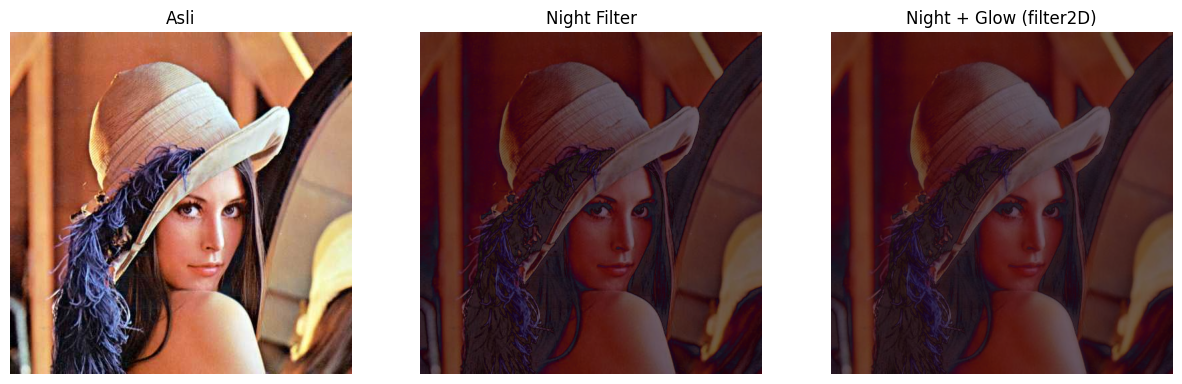

In [21]:
# Night Filter
img = cv.imread("/content/drive/MyDrive/lena.jpg") # Atau gunakan path gambar 'djawatan.jpg' sesuai modul jika ada
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# Step 1: Gelapkan (contrast turun, brightness negatif)
night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)

# Step 2: Tambah bias biru
blue_tint = np.full_like(night, (50, 0, 100)) # BGR
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)

# Step 3: Efek glow di area terang dengan filter2D (blur kernel)
kernel = np.ones((15, 15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel)

# Kombinasikan asli + glow
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)

# Tampilkan hasil
show_side_by_side([img, night, night_glow],
                  ["Asli", "Night Filter", "Night + Glow (filter2D)"])

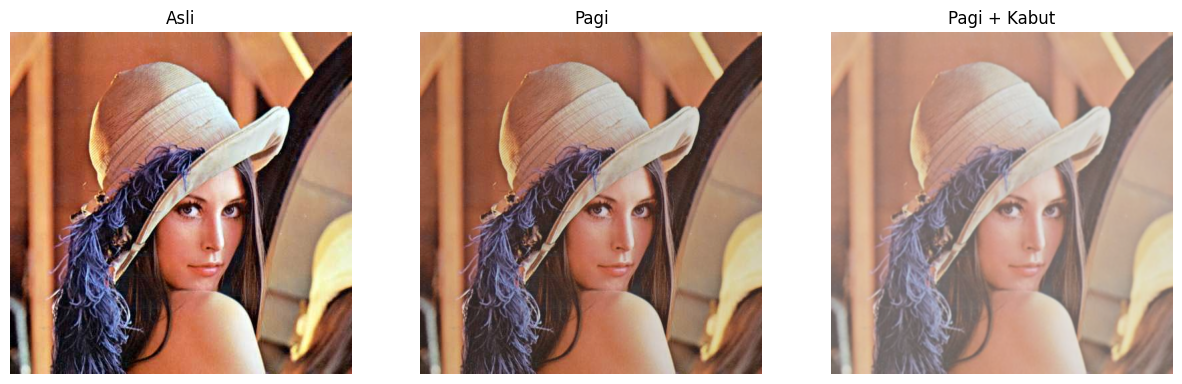

In [22]:
# Filter Suasana pagi dan Kabut
# ========================================
# Step 1: Kurangi kontras & cerahkan
# ========================================
alpha = 0.9  # contrast
beta = 20    # brightness
soft = cv.convertScaleAbs(img, alpha=alpha, beta=beta)

# ========================================
# Step 2: Tambahkan warm tone (kemerahan / oranye)
# ========================================
warm_tint = np.full_like(soft, (40, 70, 120))  # BGR
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)

# ========================================
# Step 3: Tambahkan haze (kabut tipis) dengan filter2D
# ========================================
# Kernel blur Gaussian-like untuk menciptakan efek kabut
kernel = cv.getGaussianKernel(3, 3)
kernel = kernel @ kernel.T  # jadikan 2D kernel
kabut = cv.filter2D(pagi, -1, kernel)

# tambah layer putih untuk kabut lebih nyata
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)

show_side_by_side([img, pagi, kabut],
                  ["Asli", "Pagi", "Pagi + Kabut"])

Task


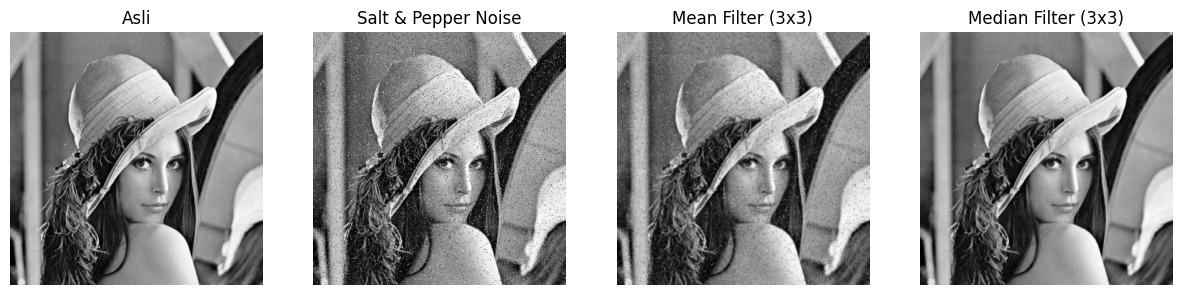

In [23]:
# a. Tambahkan speckle noise hitam dan putih (Salt and Pepper) ke citra grayscale
def add_salt_and_pepper_noise(image, prob):
    output = image.copy()
    black_threshold = prob / 2
    white_threshold = 1 - prob / 2
    rnd = np.random.rand(*image.shape)
    output[rnd < black_threshold] = 0   # Pepper (Hitam)
    output[rnd > white_threshold] = 255 # Salt (Putih)
    return output

img_noise = add_salt_and_pepper_noise(img_gray, 0.05)

# b. Terapkan Mean Filter (3x3) dan Median Filter (3x3)
mean_kernel = np.ones((3, 3), np.float32) / 9
mean_filtered = cv.filter2D(img_noise, -1, mean_kernel)
median_filtered = cv.medianBlur(img_noise, 3)

# Tampilkan hasil perbandingan
show_side_by_side([img_gray, img_noise, mean_filtered, median_filtered],
                  ["Asli", "Salt & Pepper Noise", "Mean Filter (3x3)", "Median Filter (3x3)"])

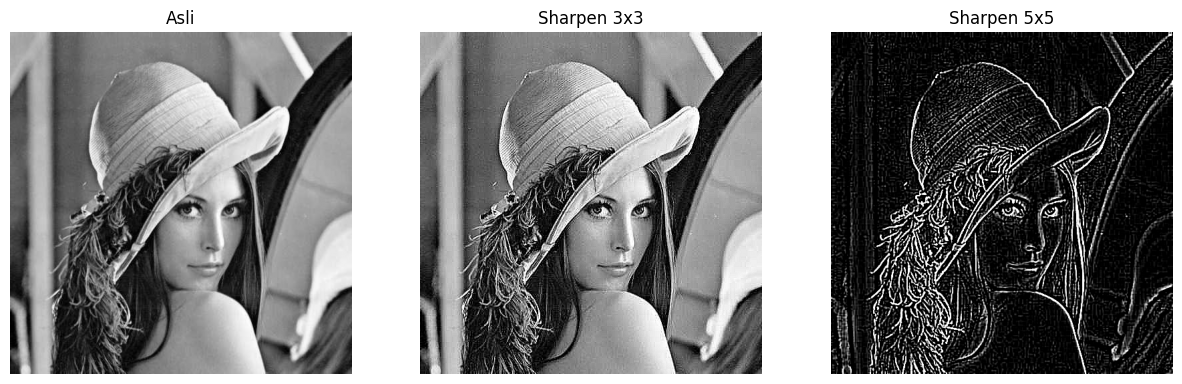

In [24]:
# a. Buat sharpening kernel ukuran 3x3 dan 5x5
kernel_3x3 = np.array([[ 0, -1,  0],
                       [-1,  5, -1],
                       [ 0, -1,  0]])

kernel_5x5 = np.array([[-1, -1, -1, -1, -1],
                       [-1,  1,  2,  1, -1],
                       [-1,  2,  4,  2, -1],
                       [-1,  1,  2,  1, -1],
                       [-1, -1, -1, -1, -1]])

# b. Terapkan pada citra
sharp_3x3 = cv.filter2D(img_gray, -1, kernel_3x3)
sharp_5x5 = cv.filter2D(img_gray, -1, kernel_5x5)

# c. Tampilkan hasil evaluasi visual
show_side_by_side([img_gray, sharp_3x3, sharp_5x5],
                  ["Asli", "Sharpen 3x3", "Sharpen 5x5"])

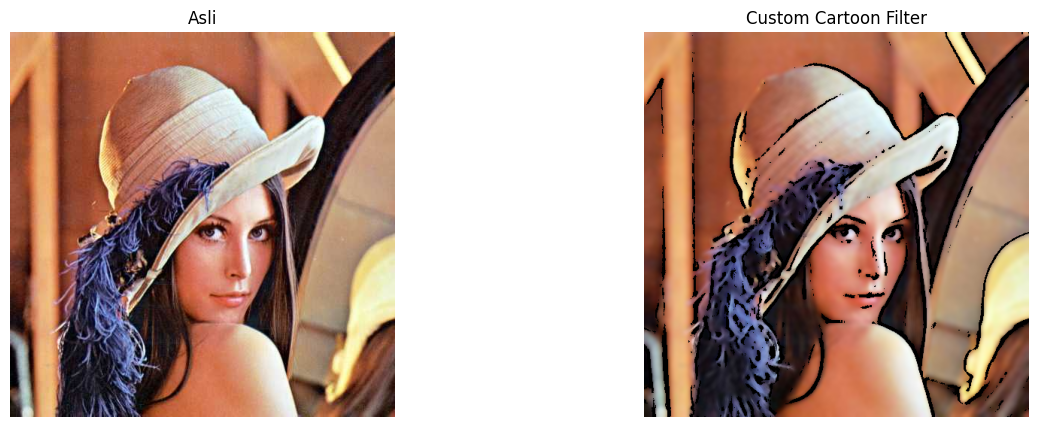

In [26]:
# a. Buat fungsi kustom cartoon(image)
def cartoon(image):
    # Refinement warna menggunakan Bilateral Filter agar area warna menjadi datar (flat)
    color = cv.bilateralFilter(image, d=9, sigmaColor=200, sigmaSpace=200)

    # Deteksi tepi menggunakan Adaptive Thresholding
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    gray_blur = cv.medianBlur(gray, 7)
    edges = cv.adaptiveThreshold(gray_blur, 255,
                                cv.ADAPTIVE_THRESH_MEAN_C,
                                cv.THRESH_BINARY, 9, 9)

    # Kombinasikan keduanya menggunakan operasi bitwise (multiplication pixels melalui mask)
    cartoon_img = cv.bitwise_and(color, color, mask=edges)
    return cartoon_img

# b. Tampilkan gambar asli dengan hasil efek kartun berdampingan
cartoon_result = cartoon(img)
show_side_by_side([img, cartoon_result], ["Asli", "Custom Cartoon Filter"])